# Subtask 1 - Depth Estimation

**Goal:** for each stereo pair under `stereo/`, produce a *depth heatmap* where
**hot colors = close** and **cold colors = far**, using both:

1. a **classical** method - `cv2.StereoSGBM` with a WLS edge-aware filter, and
2. a **machine-learning** method - **MiDaS / DPT** (`intel-isl/MiDaS` via `torch.hub`).

This notebook is fully self-contained: every helper, model wrapper, and
visualization function it needs is defined inline in the cells below.

### Dataset note

The `stereo/` folder contains six pairs:

- `road1`, `road2`, `000020` - KITTI-style outdoor (1242x375)
- `lab` - custom HD indoor (1920x1080)
- `room`, `hallway` - Nikon D3X indoor (6048x4032, downscaled before SGBM)

The pair `000020_10.png` / `000020_11.png` actually follows the KITTI-2015
*scene-flow* filename convention, where `_10` and `_11` are **two time steps of
the same camera**, not a left/right stereo pair. Real KITTI stereo uses
`image_2` (left) vs `image_3` (right). We still run SGBM on it for completeness,
but the metric results for that pair should be treated with caution; `road1` /
`road2` are the authoritative stereo-metric examples.

## 0. Setup

Imports, repo-relative paths, and all the helper code (dataset registry,
camera intrinsics, heatmap rendering, panel layout) used by every section
below. Defined once, used everywhere.

In [9]:
from __future__ import annotations

import sys
import time
from dataclasses import dataclass, field
from functools import lru_cache
from pathlib import Path
from typing import Literal

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import ExifTags, Image

# Resolve the repo root whether the notebook is run from `notebooks/` (the
# default Jupyter CWD) or from the repo root (typical on Colab).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
STEREO_DIR = ROOT / "stereo"
OUTPUTS_DIR = ROOT / "outputs"

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["figure.dpi"] = 110

print(f"ROOT       = {ROOT}")
print(f"STEREO_DIR = {STEREO_DIR} (exists={STEREO_DIR.is_dir()})")
print(f"OUTPUTS_DIR= {OUTPUTS_DIR}")

ROOT       = /Users/destroy/Documents/GitHub/CV-P4-test
STEREO_DIR = /Users/destroy/Documents/GitHub/CV-P4-test/stereo (exists=True)
OUTPUTS_DIR= /Users/destroy/Documents/GitHub/CV-P4-test/outputs


### Stereo dataset registry & loader

`PAIR_REGISTRY` is the hand-curated list of the six stereo pairs we ship.
Keeping it explicit (rather than auto-globbing the folder) lets us tag
which pairs have trustworthy KITTI calibration and which need EXIF-derived
intrinsics. `load_pair` reads BGR images and downscales anything wider than
`max_width` so SGBM stays tractable on the 24 MP Nikon shots.

In [10]:
@dataclass
class StereoPair:
    """Resolved stereo pair with metadata."""

    name: str
    left_path: Path
    right_path: Path
    is_kitti: bool = False
    focal_px_hint: float | None = None
    notes: str = ""
    tags: list[str] = field(default_factory=list)

    def exists(self) -> bool:
        return self.left_path.is_file() and self.right_path.is_file()


PAIR_REGISTRY: list[StereoPair] = [
    StereoPair(
        name="road1",
        left_path=STEREO_DIR / "left" / "road1-left.png",
        right_path=STEREO_DIR / "right" / "road1-right.png",
        is_kitti=True,
        tags=["outdoor", "kitti"],
        notes="KITTI-style road scene, 1242x375.",
    ),
    StereoPair(
        name="road2",
        left_path=STEREO_DIR / "left" / "road2-left.png",
        right_path=STEREO_DIR / "right" / "road2-right.png",
        is_kitti=True,
        tags=["outdoor", "kitti"],
        notes="KITTI-style road scene, 1242x375.",
    ),
    StereoPair(
        name="000020",
        left_path=STEREO_DIR / "left" / "000020_10.png",
        right_path=STEREO_DIR / "right" / "000020_11.png",
        is_kitti=False,  # see note below
        tags=["outdoor", "kitti-sceneflow"],
        notes=(
            "Filenames follow KITTI-2015 scene-flow convention: _10 and _11 "
            "are two time steps of the SAME camera, not a left/right pair. "
            "Treat results with caution."
        ),
    ),
    StereoPair(
        name="lab",
        left_path=STEREO_DIR / "left" / "lab-left.png",
        right_path=STEREO_DIR / "right" / "lab-right.png",
        tags=["indoor"],
        notes="Custom HD indoor pair, 1920x1080.",
    ),
    StereoPair(
        name="room",
        left_path=STEREO_DIR / "left" / "room-left.JPG",
        right_path=STEREO_DIR / "right" / "room-right.JPG",
        tags=["indoor", "nikon"],
        notes="Nikon D3X indoor, 6048x4032 - downscale before SGBM.",
    ),
    StereoPair(
        name="hallway",
        left_path=STEREO_DIR / "left" / "hallway-left.JPG",
        right_path=STEREO_DIR / "right" / "hallway-right.JPG",
        tags=["indoor", "nikon", "textureless"],
        notes="Nikon D3X indoor, 6048x4032 - large textureless walls.",
    ),
]


def discover_pairs() -> list[StereoPair]:
    """Return every registered pair whose files exist on disk."""
    return [p for p in PAIR_REGISTRY if p.exists()]


def load_pair(
    pair: StereoPair,
    max_width: int | None = 1600,
) -> tuple[np.ndarray, np.ndarray, float]:
    """Load a stereo pair as BGR arrays, downscaling very wide images.

    Returns ``(left_bgr, right_bgr, scale)``. Callers that depend on a
    pixel-space focal length must multiply it by ``scale`` to stay consistent.
    """

    left = cv2.imread(str(pair.left_path), cv2.IMREAD_COLOR)
    right = cv2.imread(str(pair.right_path), cv2.IMREAD_COLOR)
    if left is None:
        raise FileNotFoundError(f"Could not read image: {pair.left_path}")
    if right is None:
        raise FileNotFoundError(f"Could not read image: {pair.right_path}")

    if left.shape[:2] != right.shape[:2]:
        # Hand-shot JPGs sometimes differ by a few pixels; align to the left's shape.
        right = cv2.resize(right, (left.shape[1], left.shape[0]), interpolation=cv2.INTER_AREA)

    scale = 1.0
    if max_width is not None and left.shape[1] > max_width:
        scale = max_width / float(left.shape[1])
        new_w = max_width
        new_h = int(round(left.shape[0] * scale))
        left = cv2.resize(left, (new_w, new_h), interpolation=cv2.INTER_AREA)
        right = cv2.resize(right, (new_w, new_h), interpolation=cv2.INTER_AREA)

    return left, right, scale


def ensure_dir(path: Path) -> Path:
    path.mkdir(parents=True, exist_ok=True)
    return path


def output_path(subtask: str, filename: str) -> Path:
    """Resolve and create ``outputs/<subtask>/<filename>``."""
    folder = ensure_dir(OUTPUTS_DIR / subtask)
    return folder / filename


def read_exif_focal(path: Path) -> dict[str, float | str | None]:
    """Pull focal-length and camera-body fields from an image's EXIF block."""

    info: dict[str, float | str | None] = {
        "focal_length_mm": None,
        "focal_35mm": None,
        "make": None,
        "model": None,
    }
    try:
        with Image.open(path) as im:
            raw = im.getexif()
    except Exception:
        return info
    if not raw:
        return info

    tag_by_name = {ExifTags.TAGS.get(k, k): v for k, v in raw.items()}
    fl = tag_by_name.get("FocalLength")
    if fl is not None:
        try:
            info["focal_length_mm"] = float(fl)
        except (TypeError, ValueError):
            pass
    f35 = tag_by_name.get("FocalLengthIn35mmFilm")
    if f35 is not None:
        try:
            info["focal_35mm"] = float(f35)
        except (TypeError, ValueError):
            pass
    info["make"] = tag_by_name.get("Make")
    info["model"] = tag_by_name.get("Model")
    return info


pairs = discover_pairs()
print(f"{len(pairs)} stereo pairs available:")
for p in pairs:
    print(f"  - {p.name:8s} left={p.left_path.name:20s} right={p.right_path.name:20s} {p.notes}")

6 stereo pairs available:
  - road1    left=road1-left.png       right=road1-right.png      KITTI-style road scene, 1242x375.
  - road2    left=road2-left.png       right=road2-right.png      KITTI-style road scene, 1242x375.
  - 000020   left=000020_10.png        right=000020_11.png        Filenames follow KITTI-2015 scene-flow convention: _10 and _11 are two time steps of the SAME camera, not a left/right pair. Treat results with caution.
  - lab      left=lab-left.png         right=lab-right.png        Custom HD indoor pair, 1920x1080.
  - room     left=room-left.JPG        right=room-right.JPG       Nikon D3X indoor, 6048x4032 - downscale before SGBM.
  - hallway  left=hallway-left.JPG     right=hallway-right.JPG    Nikon D3X indoor, 6048x4032 - large textureless walls.


### Camera intrinsics (KITTI + EXIF fallback)

KITTI's `road1` / `road2` ship with known rectified-camera intrinsics
(`P_rect_02`). For the hand-shot indoor pairs we fall back to EXIF
metadata: `FocalLengthIn35mmFilm` if present, otherwise
`FocalLength` + a sensor-width heuristic (Nikon D3X if we recognise the
body, else a generic full-frame 36 mm sensor).

In [11]:
# KITTI 2015 rectified cam_2 (left color) parameters.
# Source: https://www.cvlibs.net/datasets/kitti/eval_stereo_flow.php?benchmark=stereo
KITTI_FOCAL_PX = 721.5377          # pixels
KITTI_BASELINE_M = 0.5372559       # meters, cam_2 -> cam_3
KITTI_CX = 609.5593                # principal point x
KITTI_CY = 172.8540                # principal point y

# Nikon D3X full-frame sensor for the hand-shot indoor pairs.
NIKON_D3X_SENSOR_WIDTH_MM = 35.9
NIKON_D3X_SENSOR_HEIGHT_MM = 24.0


@dataclass
class CameraIntrinsics:
    """Pixel-space intrinsics for the *left* camera of a pair (after resize)."""

    focal_px: float
    baseline_m: float | None
    cx: float | None = None
    cy: float | None = None
    source: str = "unknown"


def kitti_intrinsics(scale: float = 1.0) -> CameraIntrinsics:
    """Return the KITTI 2015 stereo intrinsics, scaled by a resize factor."""
    return CameraIntrinsics(
        focal_px=KITTI_FOCAL_PX * scale,
        baseline_m=KITTI_BASELINE_M,
        cx=KITTI_CX * scale,
        cy=KITTI_CY * scale,
        source="KITTI 2015 (P_rect_02)",
    )


def estimate_focal_from_exif(
    image_path: Path,
    image_width_px: int,
    fallback_35mm: float = 35.0,
) -> tuple[float, str]:
    """Estimate a pixel focal length from EXIF metadata."""

    meta = read_exif_focal(image_path)
    make = (meta.get("make") or "").strip().upper()
    model = (meta.get("model") or "").strip().upper()

    f35 = meta.get("focal_35mm")
    if isinstance(f35, (int, float)) and f35 > 0:
        focal_px = float(f35) / 36.0 * image_width_px  # full-frame is 36 mm wide
        return focal_px, f"EXIF FocalLengthIn35mmFilm={f35:.1f}mm"

    f_mm = meta.get("focal_length_mm")
    if isinstance(f_mm, (int, float)) and f_mm > 0:
        if "NIKON" in make and "D3X" in model:
            sensor_w = NIKON_D3X_SENSOR_WIDTH_MM
            src = f"EXIF FocalLength={f_mm:.1f}mm on Nikon D3X ({sensor_w:.1f}mm sensor)"
        else:
            sensor_w = 36.0
            src = f"EXIF FocalLength={f_mm:.1f}mm, assumed full-frame 36mm sensor"
        focal_px = float(f_mm) / sensor_w * image_width_px
        return focal_px, src

    focal_px = fallback_35mm / 36.0 * image_width_px
    return focal_px, f"fallback: assumed {fallback_35mm:.0f}mm equiv on full frame"


def intrinsics_for_pair(pair: StereoPair, scale: float = 1.0) -> CameraIntrinsics:
    """Choose the best-available intrinsics for ``pair`` (KITTI > EXIF > fallback)."""

    if pair.is_kitti:
        return kitti_intrinsics(scale)

    with Image.open(pair.left_path) as im:
        orig_w = im.size[0]
    focal_px_full, src = estimate_focal_from_exif(pair.left_path, orig_w)
    return CameraIntrinsics(
        focal_px=focal_px_full * scale,
        baseline_m=None,
        cx=None,
        cy=None,
        source=src,
    )

### Heatmap rendering

Convention: **hot = close, cold = far**.

`colorize_closeness` expects a "closeness" map (large values = closer);
both raw SGBM disparity and MiDaS inverse depth satisfy that. Metric
depth (in meters) is flipped via `1/Z` first by `colorize_depth`.

In [12]:
def robust_normalize(
    values: np.ndarray,
    valid_mask: np.ndarray | None = None,
    low: float = 2.0,
    high: float = 98.0,
) -> np.ndarray:
    """Normalize values to [0, 1] using percentile clipping on valid entries."""

    v = values.astype(np.float32, copy=False)
    mask = np.isfinite(v)
    if valid_mask is not None:
        mask &= valid_mask.astype(bool)
    if not mask.any():
        return np.zeros_like(v)

    lo, hi = np.percentile(v[mask], [low, high])
    if hi - lo < 1e-6:
        hi = lo + 1e-6

    out = np.clip((v - lo) / (hi - lo), 0.0, 1.0)
    out[~mask] = 0.0
    return out


def colorize_closeness(
    closeness: np.ndarray,
    valid_mask: np.ndarray | None = None,
    colormap: int = cv2.COLORMAP_TURBO,
) -> np.ndarray:
    """Colorize a closeness map (large=close) as a BGR uint8 heatmap."""

    norm = robust_normalize(closeness, valid_mask=valid_mask)
    u8 = (norm * 255.0).astype(np.uint8)
    heat = cv2.applyColorMap(u8, colormap)
    if valid_mask is not None:
        heat[~valid_mask.astype(bool)] = (50, 20, 0)  # dark blue-ish (BGR)
    return heat


def colorize_depth(
    depth_m: np.ndarray,
    valid_mask: np.ndarray | None = None,
    colormap: int = cv2.COLORMAP_TURBO,
) -> np.ndarray:
    """Colorize a metric depth map (meters). Inverts to closeness first."""

    depth = depth_m.astype(np.float32, copy=False)
    with np.errstate(divide="ignore", invalid="ignore"):
        closeness = np.where(depth > 1e-6, 1.0 / depth, 0.0)
    m = valid_mask if valid_mask is not None else (np.isfinite(depth) & (depth > 0))
    return colorize_closeness(closeness, valid_mask=m, colormap=colormap)


def overlay_on_image(
    image_bgr: np.ndarray,
    heat_bgr: np.ndarray,
    alpha: float = 0.6,
) -> np.ndarray:
    """Blend ``heat_bgr`` over a grayscale version of ``image_bgr``."""

    if image_bgr.shape[:2] != heat_bgr.shape[:2]:
        heat_bgr = cv2.resize(
            heat_bgr,
            (image_bgr.shape[1], image_bgr.shape[0]),
            interpolation=cv2.INTER_LINEAR,
        )
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    gray3 = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    return cv2.addWeighted(heat_bgr, alpha, gray3, 1.0 - alpha, 0.0)

### Visualization helpers

`hstack_panels` glues panels of different heights together with a dark
gutter; `annotate_title` prepends a black title bar. Together they build
the triptych PNGs we save under `outputs/subtask1/`. `_show_rgb` is a
matplotlib convenience used by the per-pair inline plots below.

In [13]:
def hstack_panels(
    panels: list[np.ndarray],
    gap_px: int = 8,
    background: tuple[int, int, int] = (20, 20, 20),
) -> np.ndarray:
    """Horizontally stack panels of possibly different heights."""

    panels = [p for p in panels if p is not None]
    if not panels:
        raise ValueError("No panels to stack.")

    target_h = max(p.shape[0] for p in panels)
    resized: list[np.ndarray] = []
    for p in panels:
        if p.ndim == 2:
            p = cv2.cvtColor(p, cv2.COLOR_GRAY2BGR)
        if p.shape[0] != target_h:
            scale = target_h / p.shape[0]
            new_w = int(round(p.shape[1] * scale))
            p = cv2.resize(p, (new_w, target_h), interpolation=cv2.INTER_AREA)
        resized.append(p)

    total_w = sum(p.shape[1] for p in resized) + gap_px * (len(resized) - 1)
    out = np.full((target_h, total_w, 3), background, dtype=np.uint8)
    cx = 0
    for p in resized:
        out[:, cx : cx + p.shape[1]] = p
        cx += p.shape[1] + gap_px
    return out


def annotate_title(
    image_bgr: np.ndarray,
    title: str,
    font_scale: float = 0.8,
) -> np.ndarray:
    """Prepend a black title bar to an image."""

    font = cv2.FONT_HERSHEY_SIMPLEX
    (tw, th), _ = cv2.getTextSize(title, font, font_scale, 2)
    bar_h = th + 16
    bar = np.zeros((bar_h, image_bgr.shape[1], 3), dtype=np.uint8)
    cv2.putText(
        bar,
        title,
        (10, bar_h - 8),
        font,
        font_scale,
        (240, 240, 240),
        thickness=2,
        lineType=cv2.LINE_AA,
    )
    return np.vstack([bar, image_bgr])


def _show_rgb(img_bgr: np.ndarray, title: str, ax) -> None:
    """matplotlib helper that converts BGR -> RGB and hides axes."""
    ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

## 1. Classical depth - StereoSGBM + WLS

Pipeline per pair:

1. Convert both images to grayscale.
2. Run `cv2.StereoSGBM_create` with per-scene `numDisparities` and `blockSize`
   (see the `PRESETS` dict in the next cell).
3. Refine via `cv2.ximgproc.createDisparityWLSFilter` (left + right matchers).
4. Colorize disparity directly as "closeness" - high disparity = close = hot.

WLS comes from `opencv-contrib-python` (`cv2.ximgproc`). If only the base
`opencv-python` is installed the disparity pipeline still runs, just without
the edge-preserving refinement.

In [14]:
@dataclass
class SGBMParams:
    """Parameters for ``cv2.StereoSGBM_create`` + WLS."""

    min_disparity: int = 0
    num_disparities: int = 128       # must be divisible by 16
    block_size: int = 5
    p1_factor: int = 8               # P1 = p1_factor * 3 * block_size**2
    p2_factor: int = 32              # P2 = p2_factor * 3 * block_size**2
    disp12_max_diff: int = 1
    uniqueness_ratio: int = 10
    speckle_window_size: int = 100
    speckle_range: int = 2
    pre_filter_cap: int = 63
    mode: int = cv2.STEREO_SGBM_MODE_SGBM_3WAY
    wls_lambda: float = 8000.0
    wls_sigma: float = 1.5


# Per-scene tuning. KITTI road scenes are wide/thin and well-textured; the
# Nikon indoor pairs need a much larger disparity range because objects can
# be very close to the camera.
PRESETS: dict[str, SGBMParams] = {
    "road1":   SGBMParams(num_disparities=128, block_size=5),
    "road2":   SGBMParams(num_disparities=128, block_size=5),
    "000020":  SGBMParams(num_disparities=128, block_size=5),
    "lab":     SGBMParams(num_disparities=192, block_size=7),
    "room":    SGBMParams(num_disparities=256, block_size=9, uniqueness_ratio=5),
    "hallway": SGBMParams(num_disparities=256, block_size=9, uniqueness_ratio=5),
}

DEFAULT_PARAMS = SGBMParams()


def preset_for(name: str) -> SGBMParams:
    return PRESETS.get(name, DEFAULT_PARAMS)


def _build_sgbm(params: SGBMParams, channels: int = 1) -> cv2.StereoSGBM:
    bs = params.block_size
    p1 = params.p1_factor * channels * bs * bs
    p2 = params.p2_factor * channels * bs * bs
    return cv2.StereoSGBM_create(
        minDisparity=params.min_disparity,
        numDisparities=params.num_disparities,
        blockSize=bs,
        P1=p1,
        P2=p2,
        disp12MaxDiff=params.disp12_max_diff,
        uniquenessRatio=params.uniqueness_ratio,
        speckleWindowSize=params.speckle_window_size,
        speckleRange=params.speckle_range,
        preFilterCap=params.pre_filter_cap,
        mode=params.mode,
    )


def compute_disparity(
    left_bgr: np.ndarray,
    right_bgr: np.ndarray,
    params: SGBMParams | None = None,
    use_wls: bool = True,
) -> tuple[np.ndarray, np.ndarray]:
    """Subpixel disparity from a stereo pair. Invalid entries become NaN."""

    if params is None:
        params = DEFAULT_PARAMS

    left_gray = cv2.cvtColor(left_bgr, cv2.COLOR_BGR2GRAY)
    right_gray = cv2.cvtColor(right_bgr, cv2.COLOR_BGR2GRAY)

    left_matcher = _build_sgbm(params, channels=1)

    if use_wls and hasattr(cv2, "ximgproc"):
        right_matcher = cv2.ximgproc.createRightMatcher(left_matcher)
        disp_left_raw = left_matcher.compute(left_gray, right_gray)
        disp_right_raw = right_matcher.compute(right_gray, left_gray)
        wls = cv2.ximgproc.createDisparityWLSFilter(left_matcher)
        wls.setLambda(params.wls_lambda)
        wls.setSigmaColor(params.wls_sigma)
        disp_raw = wls.filter(disp_left_raw, left_gray, disparity_map_right=disp_right_raw)
    else:
        disp_raw = left_matcher.compute(left_gray, right_gray)

    # StereoSGBM returns disparity scaled by 16 as int16.
    disp = disp_raw.astype(np.float32) / 16.0

    # The second condition filters WLS overshoot in occluded / border regions.
    max_valid_disp = float(params.min_disparity + params.num_disparities)
    valid = (disp > (params.min_disparity + 0.5)) & (disp < max_valid_disp)
    disp = np.where(valid, disp, np.nan)
    return disp, valid


def disparity_to_depth(
    disparity_px: np.ndarray,
    focal_px: float,
    baseline_m: float,
    clip_max_m: float | None = 200.0,
) -> tuple[np.ndarray, np.ndarray]:
    """Convert disparity (px) to metric depth via ``Z = f*B/d``."""

    disp = disparity_px.astype(np.float32, copy=False)
    valid = np.isfinite(disp) & (disp > 1e-3)

    depth = np.full_like(disp, np.nan, dtype=np.float32)
    with np.errstate(divide="ignore", invalid="ignore"):
        depth[valid] = focal_px * baseline_m / disp[valid]

    if clip_max_m is not None:
        too_far = np.isfinite(depth) & (depth > clip_max_m)
        depth[too_far] = np.nan
        valid &= ~too_far

    return depth, valid

In [15]:
def run_classical(pair: StereoPair, max_width: int = 1600) -> dict:
    """Full classical pipeline for one pair: SGBM + heatmap + (optional) metric depth."""

    left, right, scale = load_pair(pair, max_width=max_width)
    params = preset_for(pair.name)
    disp, valid = compute_disparity(left, right, params=params, use_wls=True)

    intrinsics = intrinsics_for_pair(pair, scale=scale)
    depth_m = None
    if pair.is_kitti and intrinsics.baseline_m is not None:
        depth_m, _ = disparity_to_depth(
            disp, focal_px=intrinsics.focal_px, baseline_m=intrinsics.baseline_m
        )

    heat = colorize_closeness(disp, valid_mask=valid)
    overlay = overlay_on_image(left, heat, alpha=0.65)
    return dict(
        left=left, right=right, scale=scale,
        disparity=disp, valid=valid, depth_m=depth_m, intrinsics=intrinsics,
        heat=heat, overlay=overlay, params=params,
    )


classical_results: dict[str, dict] = {}
for pair in pairs:
    print(f"Running SGBM on {pair.name}...")
    classical_results[pair.name] = run_classical(pair)
print("Done.")

Running SGBM on road1...
Running SGBM on road2...
Running SGBM on 000020...
Running SGBM on lab...
Running SGBM on room...
Running SGBM on hallway...
Done.


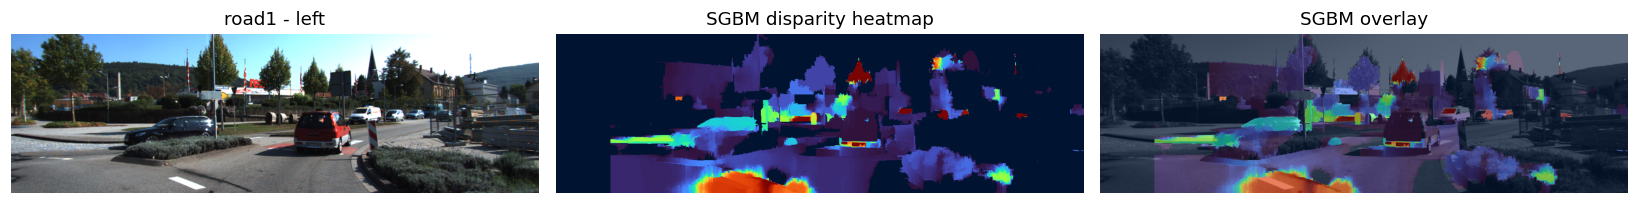

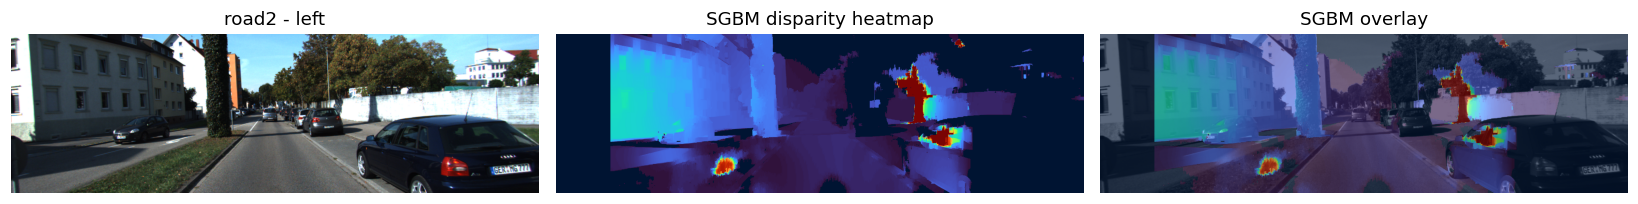

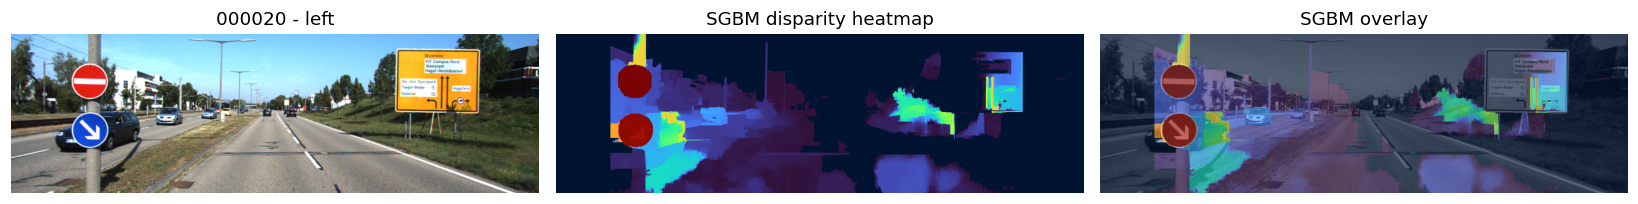

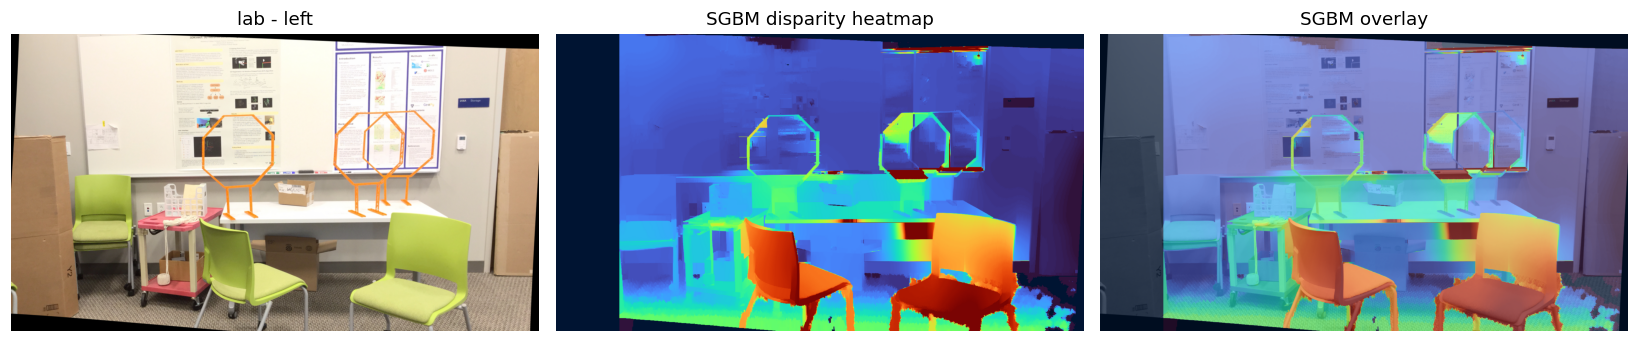

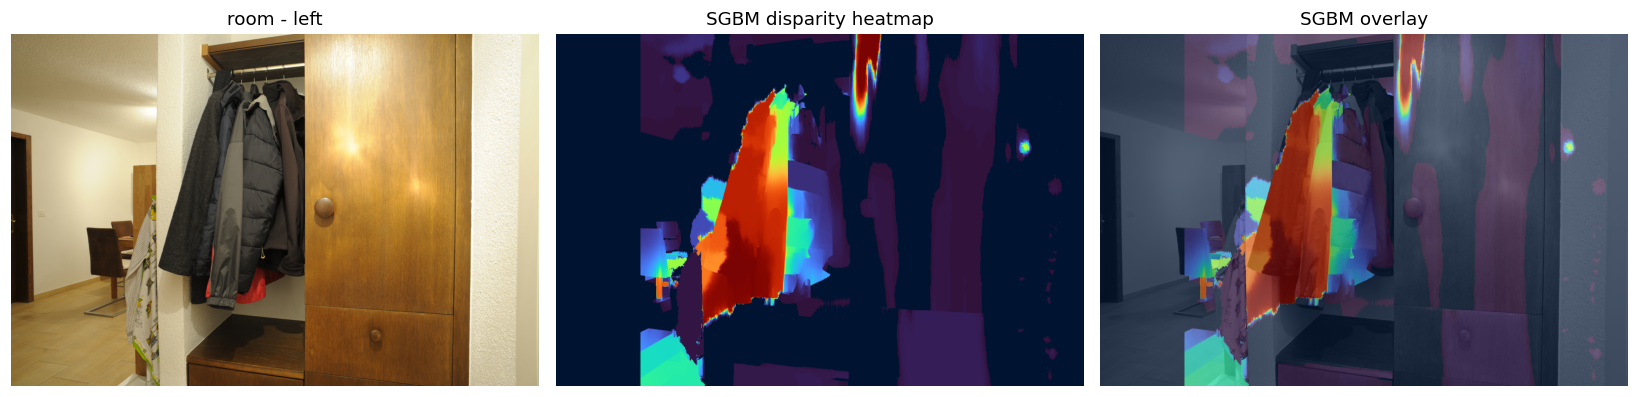

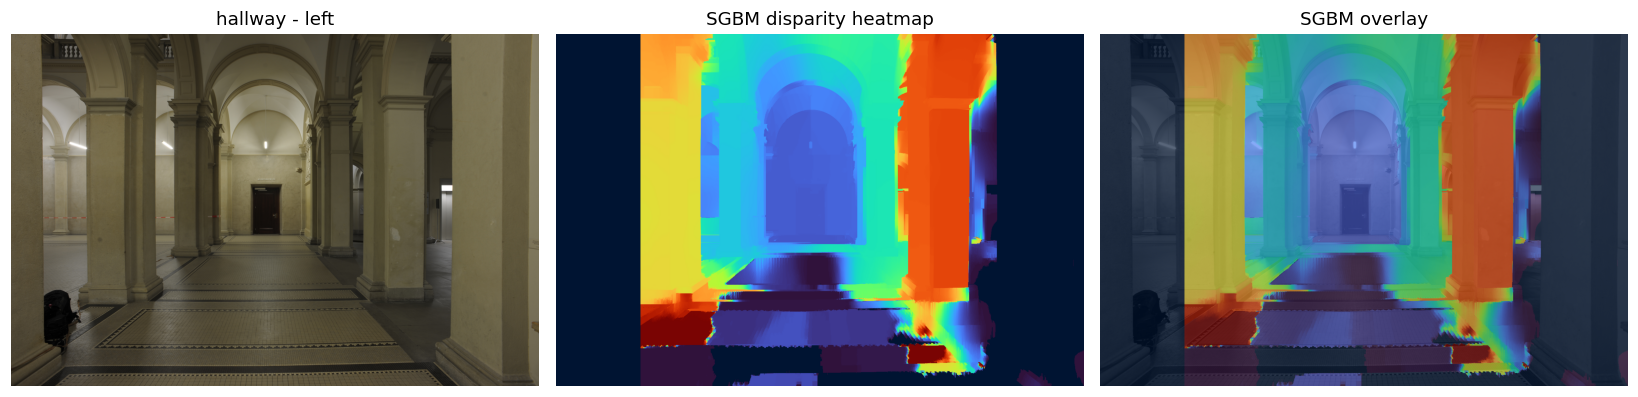

In [16]:
for pair in pairs:
    r = classical_results[pair.name]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    _show_rgb(r["left"], f"{pair.name} - left", axes[0])
    _show_rgb(r["heat"], "SGBM disparity heatmap", axes[1])
    _show_rgb(r["overlay"], "SGBM overlay", axes[2])
    fig.tight_layout()
    plt.show()